## 1. Data Overview

Inspect the dataset's structure, data types, missing values,
and descriptive statistics before beginning feature engineering.

In [3]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_parquet(
    PROJECT_ROOT / "data/processed/hourly_power.parquet"
)

df.head()

,timestamp,mean_power_kw,valid_minutes
0,2006-12-16 17:00:00,4.222889,36
1,2006-12-16 18:00:00,3.632200,60
2,2006-12-16 19:00:00,3.400233,60
3,2006-12-16 20:00:00,3.268567,60
4,2006-12-16 21:00:00,3.056467,60


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34589 entries, 0 to 34588
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp      34589 non-null  datetime64[ns]
 1   mean_power_kw  34168 non-null  float64       
 2   valid_minutes  34589 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 810.8 KB


In [5]:
df.describe()

,timestamp,mean_power_kw,valid_minutes
count,34589,34168.000000,34589.000000
mean,2008-12-06 07:00:00,1.091728,59.246581
min,2006-12-16 17:00:00,0.124000,0.000000
25%,2007-12-12 00:00:00,0.341925,60.000000
50%,2008-12-06 07:00:00,0.802850,60.000000
75%,2009-12-01 14:00:00,1.579342,60.000000
max,2010-11-26 21:00:00,6.560533,60.000000
std,NaN,0.897619,6.636243


## 2. Electricity Demand Distribution

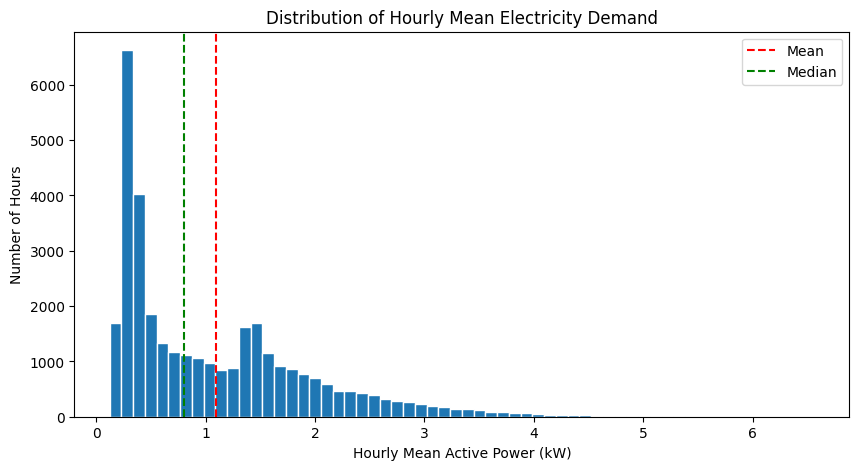

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["mean_power_kw"].dropna(),
    bins=60,
    edgecolor="white"
)

plt.axvline(
    df["mean_power_kw"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    df["mean_power_kw"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.title("Distribution of Hourly Mean Electricity Demand")
plt.xlabel("Hourly Mean Active Power (kW)")
plt.ylabel("Number of Hours")
plt.legend()
plt.show()

### Initial Findings — Electricity Demand Distribution

- Hourly mean electricity demand is positively (right) skewed.
- The mean (1.09 kW) exceeds the median (0.80 kW), indicating that higher-demand periods influence the overall average.
- Most observations are concentrated at relatively low demand levels.
- A secondary concentration appears around 1.4–1.6 kW, suggesting a possible recurring consumption pattern that warrants further investigation.
- High-demand hours above approximately 4 kW are relatively uncommon.

**Next question:** How does electricity demand vary by hour of day, and could recurring daily patterns help us forecast future consumption?

## 3. Daily Electricity Demand Patterns

In [13]:
# Extract the hour of day (0–23) from each timestamp.
df["hour"] = df["timestamp"].dt.hour

# Calculate average demand for each hour.
hourly_pattern = df.groupby("hour")["mean_power_kw"].mean()

hourly_pattern

hour
0     0.659562
1     0.539325
2     0.480618
3     0.444850
4     0.443844
5     0.453674
6     0.791606
7     1.502373
8     1.460940
9     1.331642
10    1.260913
11    1.246408
12    1.207061
13    1.144471
14    1.082750
15    0.990806
16    0.948805
17    1.056164
18    1.326433
19    1.733428
20    1.899073
21    1.876063
22    1.412681
23    0.902142
Name: mean_power_kw, dtype: float64

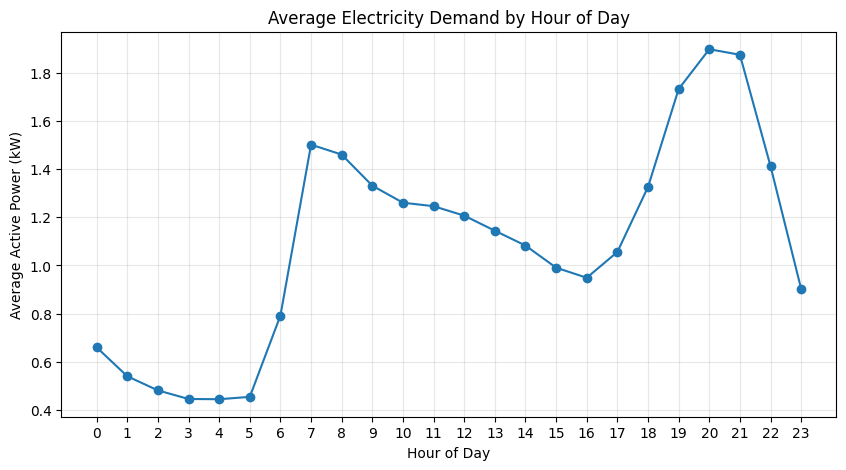

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern.values,
    marker="o"
)

plt.title("Average Electricity Demand by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

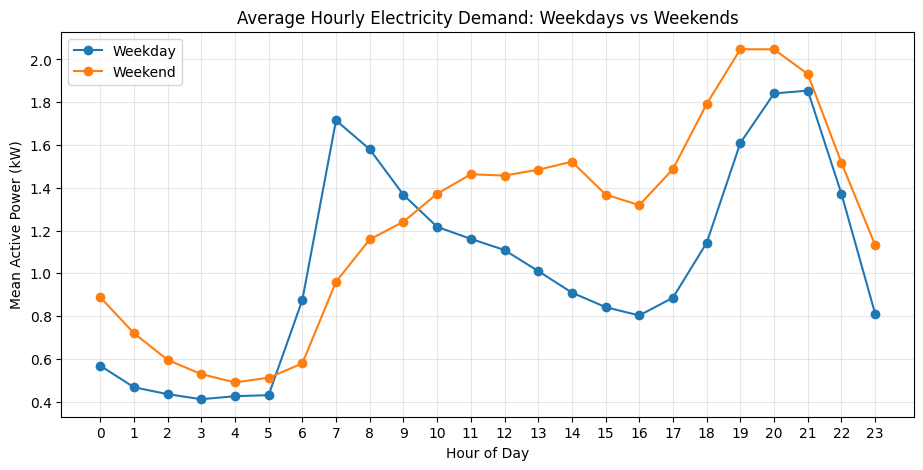

In [15]:
df["day_of_week"] = df["timestamp"].dt.dayofweek

df["is_weekend"] = df["day_of_week"] >= 5

week_pattern = (
    df.groupby(["is_weekend", "hour"])["mean_power_kw"]
    .mean()
    .unstack(level=0)
)

week_pattern.columns = ["Weekday", "Weekend"]

week_pattern.plot(
    figsize=(11, 5),
    marker="o",
    title="Average Hourly Electricity Demand: Weekdays vs Weekends"
)

plt.xlabel("Hour of Day")
plt.ylabel("Mean Active Power (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

### Findings — Weekday vs. Weekend Demand

- Weekday electricity demand exhibits a pronounced morning peak around 7 AM, followed by declining daytime consumption.
- Weekend demand rises more gradually during the morning and remains elevated throughout much of the afternoon.
- Weekend afternoon demand is substantially higher than weekday afternoon demand.
- Both weekday and weekend consumption peak during the evening, with weekend peaks appearing slightly earlier and higher.
- These differences suggest that `hour`, `day_of_week`, and `is_weekend` may be useful forecasting features.
- The relationship between hour and electricity demand appears to depend on whether the observation occurs on a weekday or weekend.

**Hypothesis outcome:** Partially supported. Weekend morning demand rises later, but the data shows a broader daytime consumption pattern rather than a distinct morning peak shifted by 1–2 hours.

## 4. Seasonal Electricity Demand Patterns

In [19]:
# Extract month from each timestamp
df["month"] = df["timestamp"].dt.month

# Map months to meteorological seasons
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

df["season"] = df["month"].map(season_map)

df[["timestamp", "month", "season"]].head()

,timestamp,month,season
0,2006-12-16 17:00:00,12,Winter
1,2006-12-16 18:00:00,12,Winter
2,2006-12-16 19:00:00,12,Winter
3,2006-12-16 20:00:00,12,Winter
4,2006-12-16 21:00:00,12,Winter


In [20]:
seasonal_pattern = (
    df.groupby(["season", "hour"])["mean_power_kw"]
    .mean()
    .unstack(level=0)
)

seasonal_pattern = seasonal_pattern[
    ["Winter", "Spring", "Summer", "Fall"]
]

seasonal_pattern.head()

season,Winter,Spring,Summer,Fall
hour,,,,
0,0.843638,0.621579,0.579561,0.602436
1,0.679146,0.537072,0.450134,0.497226
2,0.605567,0.491999,0.377913,0.452534
3,0.556889,0.466163,0.349003,0.412126
4,0.564760,0.444483,0.362457,0.408995


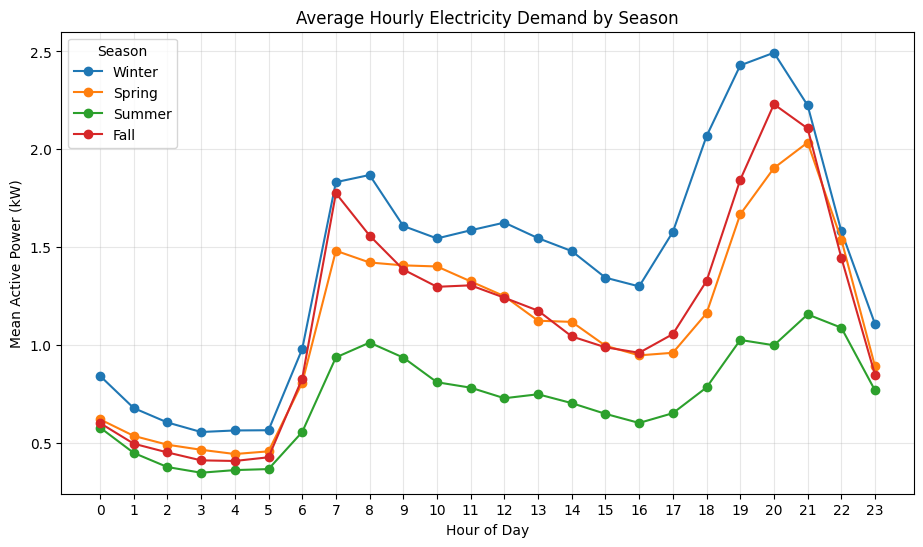

In [21]:
seasonal_pattern.plot(
    figsize=(11, 6),
    marker="o",
    title="Average Hourly Electricity Demand by Season"
)

plt.xlabel("Hour of Day")
plt.ylabel("Mean Active Power (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(title="Season")
plt.show()

### Findings — Seasonal Electricity Demand

- Electricity demand varies across seasons, suggesting that seasonal patterns may be useful for forecasting.
- Winter is expected to have higher demand in households that rely heavily on electric heating.
- Summer electricity demand may be higher in households with significant air-conditioning usage.
- Spring and fall may exhibit lower demand due to reduced heating and cooling needs.
- Seasonal electricity patterns depend on climate, household characteristics, heating and cooling equipment, and consumer behavior.
- The current dataset does not include weather measurements or detailed household equipment information, so the causes of seasonal differences cannot be confirmed.

**Modeling implication:** Calendar-based seasonal features may improve forecasting, but models trained on one household or climate may not generalize to other locations or changing energy systems.

## 5. Year-over-Year Electricity Demand

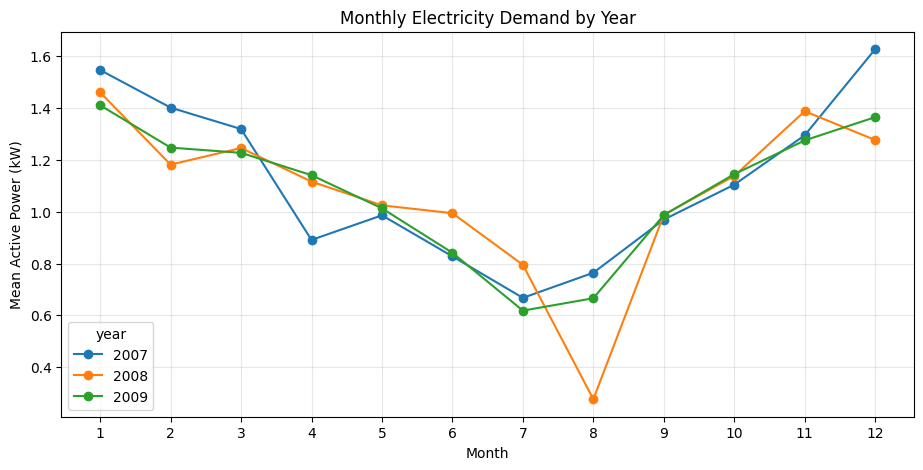

In [23]:
# Extract the year from each timestamp
df["year"] = df["timestamp"].dt.year

# Exclude incomplete calendar years for a fairer comparison
full_years = df[df["year"].between(2007, 2009)]

# Calculate mean hourly power by year and month
yearly_monthly = (
    full_years.groupby(["year", "month"])["mean_power_kw"]
    .mean()
    .unstack(level=0)
)

yearly_monthly.plot(
    figsize=(11, 5),
    marker="o",
    title="Monthly Electricity Demand by Year"
)

plt.xlabel("Month")
plt.ylabel("Mean Active Power (kW)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

In [24]:
august_2008 = df[
    (df["timestamp"].dt.year == 2008) &
    (df["timestamp"].dt.month == 8)
].copy()

print("Hours:", len(august_2008))
print("Fully missing hours:", (august_2008["valid_minutes"] == 0).sum())
print("Incomplete hours:", (august_2008["valid_minutes"] < 60).sum())
print("Average power:", august_2008["mean_power_kw"].mean())

Hours: 744
Fully missing hours: 0
Incomplete hours: 2
Average power: 0.2765574608164753


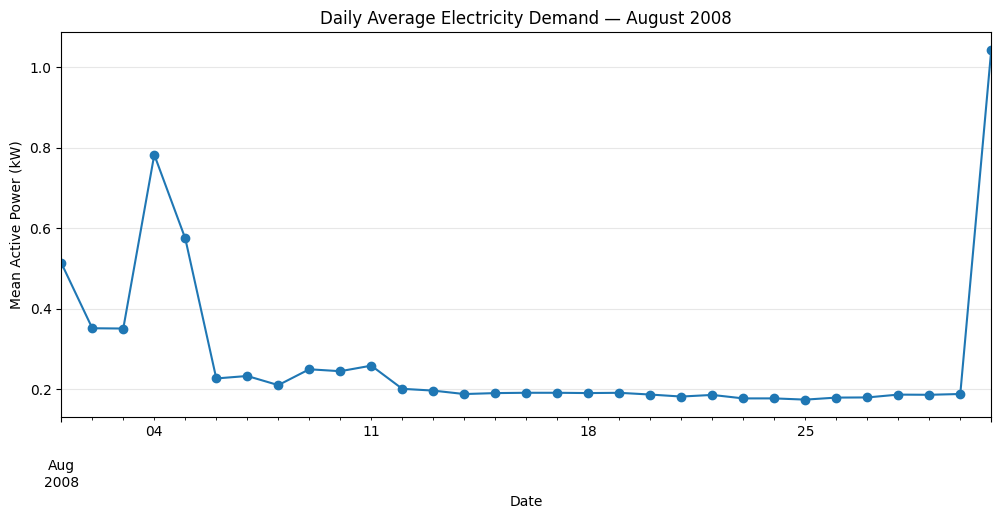

In [25]:
august_daily = (
    august_2008
    .set_index("timestamp")["mean_power_kw"]
    .resample("D")
    .mean()
)

august_daily.plot(
    figsize=(12, 5),
    marker="o",
    title="Daily Average Electricity Demand — August 2008"
)

plt.xlabel("Date")
plt.ylabel("Mean Active Power (kW)")
plt.grid(alpha=0.3)
plt.show()

### EDA Finding — August 2008 Low-Demand Period

August 2008 exhibits an unusually prolonged period of low household electricity consumption.

**Observations:**
- All 744 expected hourly timestamps are present.
- No hours are fully missing, and only two hours contain incomplete measurements.
- Monthly mean active power is approximately 0.277 kW.
- Demand becomes unusually stable around 0.18–0.20 kW during the latter half of August.
- Electricity consumption increases sharply on August 31.

**Hypothesis:** The pattern may reflect an extended period of household inactivity or absence, potentially a vacation. However, occupancy cannot be confirmed from electricity data alone.

**ML implications:**
- Unusual behavioral patterns may produce significant forecasting errors.
- Recent consumption features may help models adapt to sustained changes.
- Sudden returns to normal activity may be difficult to forecast.
- Low-demand periods could be useful for future unsupervised anomaly-detection experiments.

**Next investigation:** Examine hourly consumption during the low-demand interval to determine whether the normal morning and evening peaks disappear.

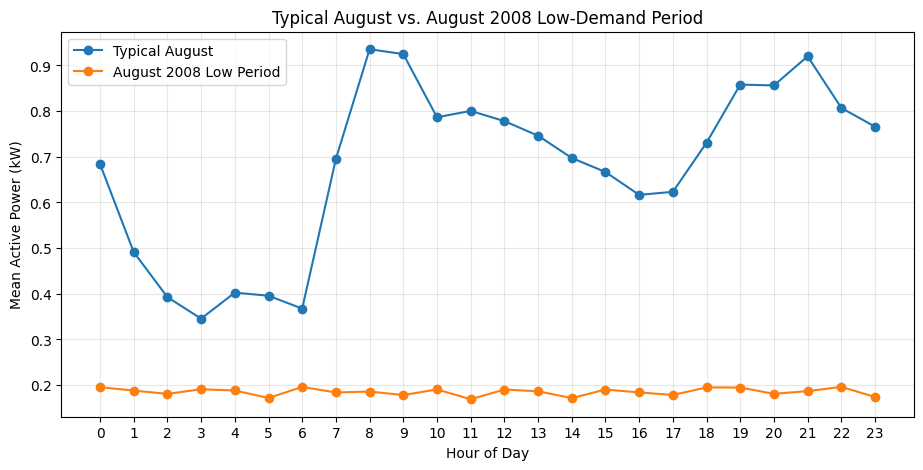

In [26]:
# Compare typical hourly demand with the low-demand period.
low_period = df[
    (df["timestamp"] >= "2008-08-13") &
    (df["timestamp"] < "2008-08-31")
]

comparison = pd.DataFrame({
    "Typical August": df[
        (df["timestamp"].dt.month == 8) &
        (df["timestamp"].dt.year != 2008)
    ].groupby("hour")["mean_power_kw"].mean(),

    "August 2008 Low Period": low_period.groupby("hour")["mean_power_kw"].mean()
})

comparison.plot(
    figsize=(11, 5),
    marker="o",
    title="Typical August vs. August 2008 Low-Demand Period"
)

plt.xlabel("Hour of Day")
plt.ylabel("Mean Active Power (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

### EDA Finding — Sustained Low-Demand Anomaly (August 2008)

A comparison of typical August consumption against August 13–30, 2008, reveals a pronounced change in household electricity usage.

**Observations:**
- Typical August consumption exhibits distinct morning and evening peaks.
- During August 13–30, 2008, hourly mean power remains approximately 0.18–0.20 kW throughout the day.
- Normal daily demand peaks are largely absent.
- The period has sufficient measurement coverage, making widespread missing data an unlikely explanation.
- Electricity demand returns sharply toward typical levels on August 31.

**Interpretation:** The pattern is consistent with a prolonged period of reduced household activity or possible absence. The underlying cause cannot be verified from the available measurements.

**ML relevance:** This is a potential collective anomaly: an unusual sequence of observations rather than a single extreme value. It may be useful for future experiments in time-series anomaly detection, change-point detection, and forecasting robustness.

**Limitation:** This interval does not constitute a verified equipment fault or labeled anomaly.

## 6. Missing Data Analysis

Investigate missing and incomplete hourly measurements,
including the duration and frequency of missing-data gaps.

In [27]:
# Categorize hourly observations by completeness
df["data_quality"] = "Complete"

df.loc[
    df["valid_minutes"] < 60,
    "data_quality"
] = "Partial"

df.loc[
    df["valid_minutes"] == 0,
    "data_quality"
] = "Missing"

# Count observations in each category
df["data_quality"].value_counts()

data_quality
Complete    34085
Missing       421
Partial        83
Name: count, dtype: int64

In [28]:
# Identify hours with no valid readings
missing = df["valid_minutes"].eq(0)

# Assign a group number whenever missing status changes
groups = missing.ne(missing.shift()).cumsum()

# Summarize consecutive missing-hour groups
missing_gaps = (
    df.loc[missing]
    .groupby(groups[missing])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        hours=("timestamp", "size")
    )
    .sort_values("hours", ascending=False)
)

missing_gaps.head(10)

,start,end,hours
valid_minutes,,,
14,2010-08-17 22:00:00,2010-08-22 20:00:00,119
16,2010-09-25 04:00:00,2010-09-28 18:00:00,87
2,2007-04-28 01:00:00,2007-04-30 13:00:00,61
6,2009-06-13 01:00:00,2009-06-15 06:00:00,54
10,2010-01-12 15:00:00,2010-01-14 18:00:00,52
12,2010-03-20 04:00:00,2010-03-21 12:00:00,33
8,2009-08-13 05:00:00,2009-08-13 18:00:00,14
4,2007-07-15 17:00:00,2007-07-15 17:00:00,1


### EDA Finding — Missing-Data Patterns

The hourly dataset contains 421 fully missing observations distributed across eight consecutive missing-data gaps.

**Key observations:**
- The longest missing interval spans 119 hours, approximately five days.
- Other substantial gaps last 87, 61, 54, 52, and 33 hours.
- Missingness is concentrated in a small number of multi-day intervals rather than scattered uniformly.
- Several of the longest gaps occur in 2010.
- An additional 83 hours contain partially observed measurements.

**Initial modeling decision:**
- Preserve missing values rather than replacing them with zero.
- Require complete hourly observations for the initial forecasting baseline.
- Exclude forecast examples with unavailable historical inputs or target observations.
- Revisit causal imputation and missingness indicators in later experiments.

**ML implication:** Missing-data handling must account for time-dependent features and forecasting horizons to prevent misleading results or data leakage.